In [1]:
print("test")

test


In [2]:
PATHS = ["../datasets/HuggingFaceM4/ChartQA/data/train-00000-of-00003-49492f364babfa44.parquet", 
        "../datasets/HuggingFaceM4/ChartQA/data/train-00001-of-00003-7302bae5e425bbc7.parquet",
        "../datasets/HuggingFaceM4/ChartQA/data/train-00002-of-00003-194c9400785577a2.parquet" 
        ]

In [3]:
import pandas as pd

# Load only the first few rows to inspect the structure

df_preview = pd.read_parquet(PATHS[0], engine="pyarrow").head()
print(df_preview.info())
print(df_preview.columns)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   image             5 non-null      object
 1   query             5 non-null      object
 2   label             5 non-null      object
 3   human_or_machine  5 non-null      int64 
dtypes: int64(1), object(3)
memory usage: 288.0+ bytes
None
Index(['image', 'query', 'label', 'human_or_machine'], dtype='object')


In [4]:
import io
import matplotlib.pyplot as plt
from PIL import Image

def decode_chart_image(row, image_col='image'):
    val = row[image_col]
    if isinstance(val, dict) and 'bytes' in val:
        return Image.open(io.BytesIO(val['bytes']))
    elif isinstance(val, bytes):
        return Image.open(io.BytesIO(val))
    elif isinstance(val, str):
        return Image.open(val)
    else:
        raise ValueError("Unsupported image column format. Ensure it contains bytes or paths.")




In [5]:
df_sample_train_0 = pd.read_parquet(PATHS[0], engine="pyarrow").head()

In [8]:
import time
import torch
import pandas as pd


# --- config ---
N_TEST = 10                      # raise once happy
test_df = df_sample_train_0.head(N_TEST)

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print("device:", device)



device: mps


In [9]:
from transformers import (
    Pix2StructForConditionalGeneration, Pix2StructProcessor,
)
# --- DePlot ---
dp_proc = Pix2StructProcessor.from_pretrained("google/deplot")
dp_model = Pix2StructForConditionalGeneration.from_pretrained("google/deplot").to(device).eval()

def deplot_table(img):
    inputs = dp_proc(images=img, text="Generate underlying data table of the figure below:",
                     return_tensors="pt").to(device)
    with torch.no_grad():
        out = dp_model.generate(**inputs, max_new_tokens=512)
    return dp_proc.decode(out[0], skip_special_tokens=True).replace("<0x0A>", "\n")



/Users/rishavbhagat/developer/ChartQA-IIITH/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1017 09:10:17.871000 18315 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 285/285 [00:00<00:00, 7159.06it/s]


In [10]:
from transformers import (
    DonutProcessor, VisionEncoderDecoderModel,
)


# --- UniChart ---
uc_name = "ahmed-masry/unichart-base-960"
uc_proc = DonutProcessor.from_pretrained(uc_name)
uc_model = VisionEncoderDecoderModel.from_pretrained(uc_name).to(device).eval()

def unichart_table(img):
    prompt = "<extract_data_table> <s_answer>"
    decoder_ids = uc_proc.tokenizer(prompt, add_special_tokens=False, return_tensors="pt").input_ids
    pixel_values = uc_proc(img, return_tensors="pt").pixel_values
    with torch.no_grad():
        out = uc_model.generate(
            pixel_values.to(device),
            decoder_input_ids=decoder_ids.to(device),
            max_length=uc_model.decoder.config.max_position_embeddings,
            pad_token_id=uc_proc.tokenizer.pad_token_id,
            eos_token_id=uc_proc.tokenizer.eos_token_id,
            use_cache=True,
            num_beams=4,
            return_dict_in_generate=True,
        )
    seq = uc_proc.tokenizer.batch_decode(out.sequences)[0]
    seq = seq.replace(uc_proc.tokenizer.eos_token, "").replace(uc_proc.tokenizer.pad_token, "")
    return seq.split("<s_answer>")[-1].strip()



Loading weights: 100%|██████████| 484/484 [00:00<00:00, 34971.20it/s]


In [11]:
# --- run on the test sample ---
def label_in(text, label):
    """Crude check: is the ground-truth answer present in the extracted table?"""
    return str(label[0]).lower() in text.lower()

results = []
for _, row in test_df.iterrows():
    img = decode_chart_image(row).convert("RGB")

    t0 = time.time(); dp = deplot_table(img);   t_dp = time.time() - t0
    t0 = time.time(); uc = unichart_table(img); t_uc = time.time() - t0

    results.append({
        "query": row["query"],
        "label": row["label"],
        "deplot_table": dp,
        "unichart_table": uc,
        "deplot_s": round(t_dp, 2),
        "unichart_s": round(t_uc, 2),
        "deplot_has_label": label_in(dp, row["label"]),
        "unichart_has_label": label_in(uc, row["label"]),
    })

df_ocr = pd.DataFrame(results)

# summary
print(df_ocr[["deplot_s", "unichart_s"]].mean().round(2).to_string())
print(df_ocr[["deplot_has_label", "unichart_has_label"]].mean().round(2).to_string())

# eyeball a few
for i in range(3):
    r = df_ocr.iloc[i]
    print(f"\n=== Q: {r['query']} | label: {r['label']} ===")
    print("--- DePlot ---\n", r["deplot_table"])
    print("--- UniChart ---\n", r["unichart_table"])

[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

deplot_s      7.71
unichart_s    1.98
deplot_has_label      0.6
unichart_has_label    0.6

=== Q: Is the value of Favorable 38 in 2015? | label: ['Yes'] ===
--- DePlot ---
 Year | Favorable | Unfavorable 
 2005 | 0 | 35 
 2007 | 5250 | 39 
 2009 | 50 | 38 
 2011 | 49 | 36 
 2013 | 35 | 52 
 2015 | 38 | 54
--- UniChart ---
 Characteristic | Unfavorable | favorable & 2005.0 | 52% | 35% & 2007.0 | 42% | 39% & 2009.0 | 49% | 38% & 2011.0 | 51% | 36% & 2013.0 | 55% | 37% & 2015.0 | 54% | 38%

=== Q: How many values are below 40 in Unfavorable graph? | label: ['6'] ===
--- DePlot ---
 Year | Favorable | Unfavorable 
 2005 | 0 | 35 
 2007 | 5250 | 39 
 2009 | 50 | 38 
 2011 | 49 | 36 
 2013 | 35 | 52 
 2015 | 38 | 54
--- UniChart ---
 Characteristic | Unfavorable | favorable & 2005.0 | 52% | 35% & 2007.0 | 42% | 39% & 2009.0 | 49% | 38% & 2011.0 | 51% | 36% & 2013.0 | 55% | 37% & 2015.0 | 54% | 38%

=== Q: In which year the value was 51? | label: ['2014'] ===
--- DePlot ---
 Year | Favorable 

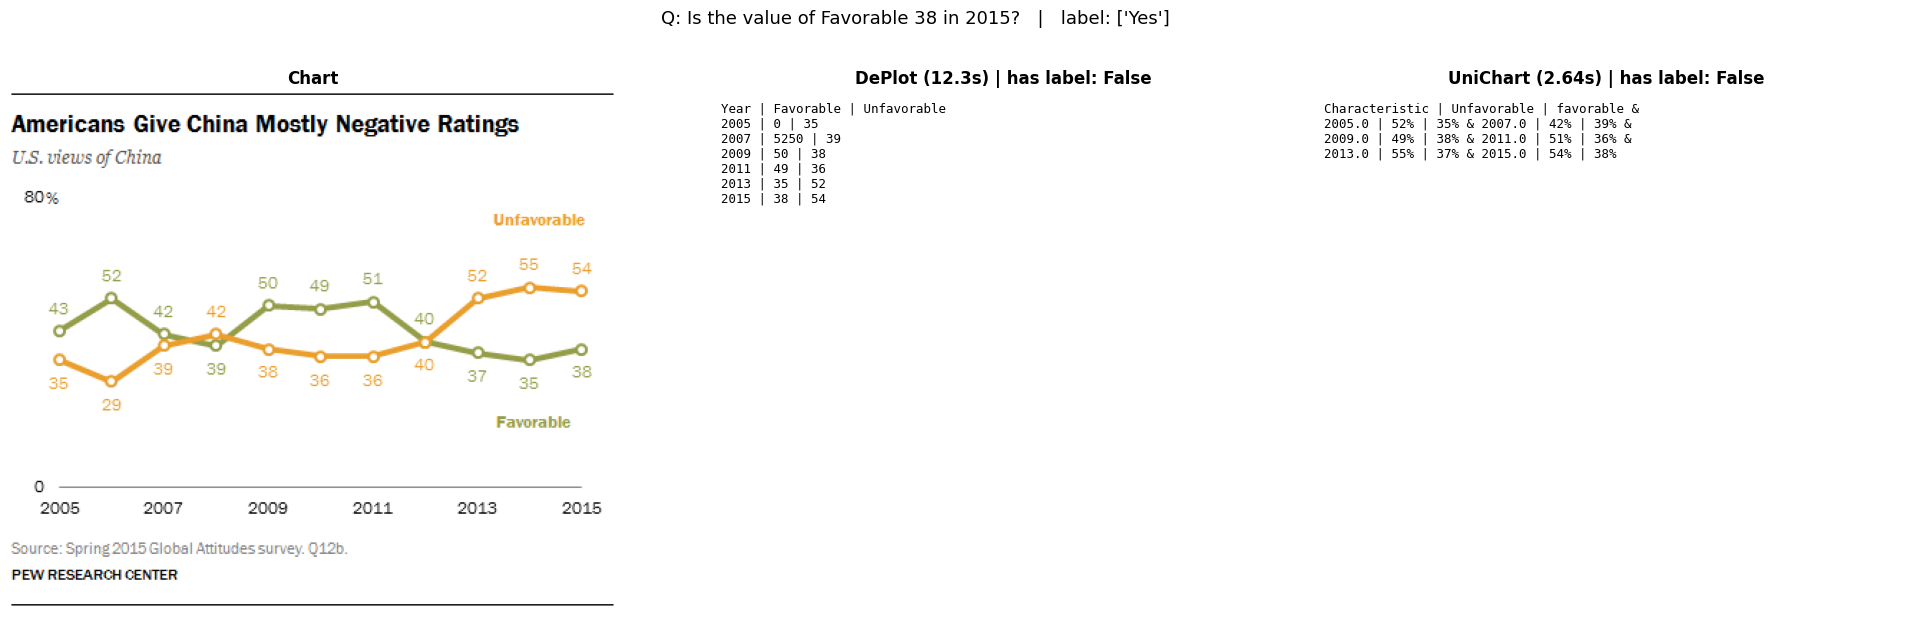

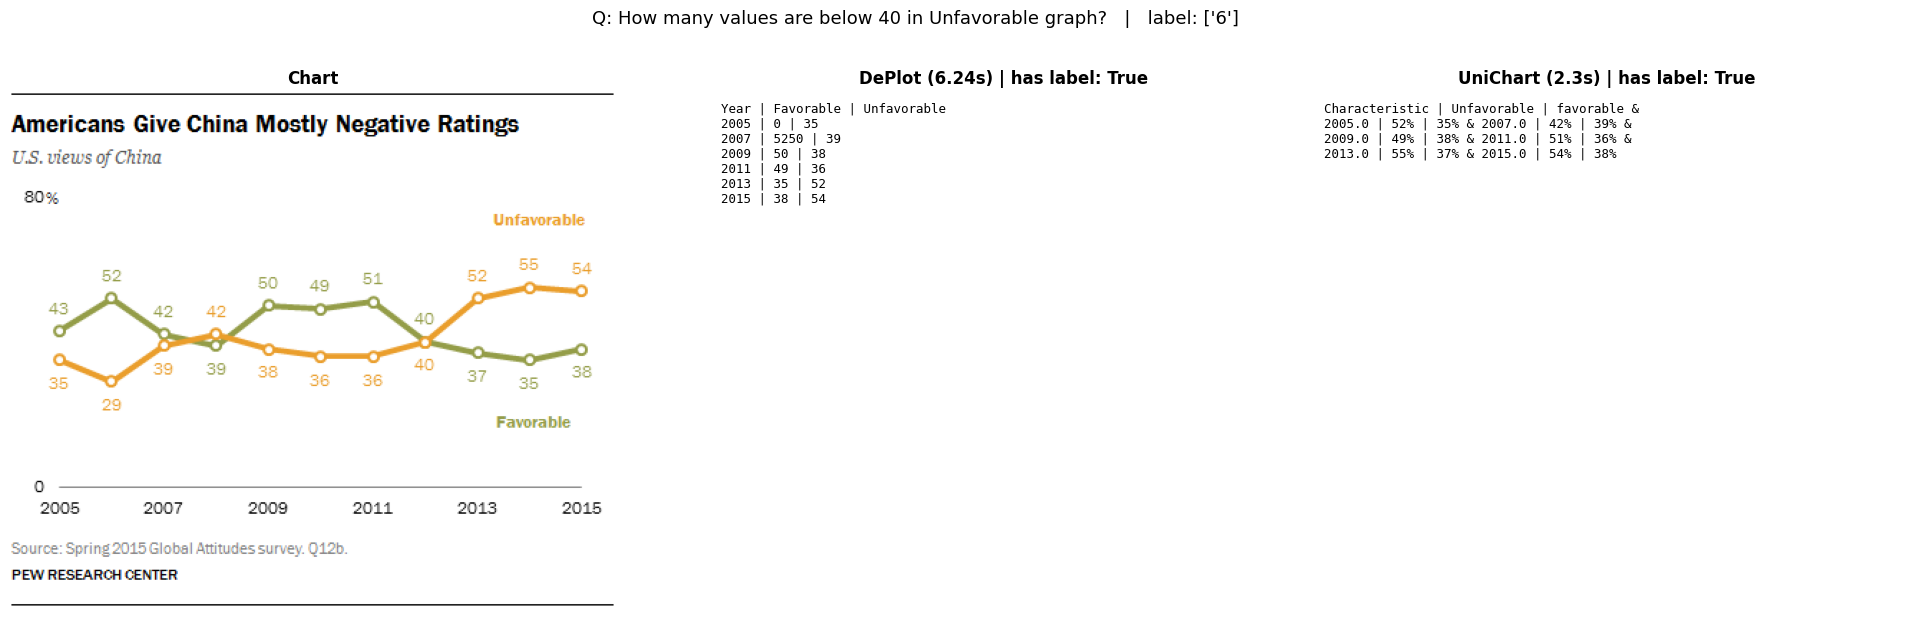

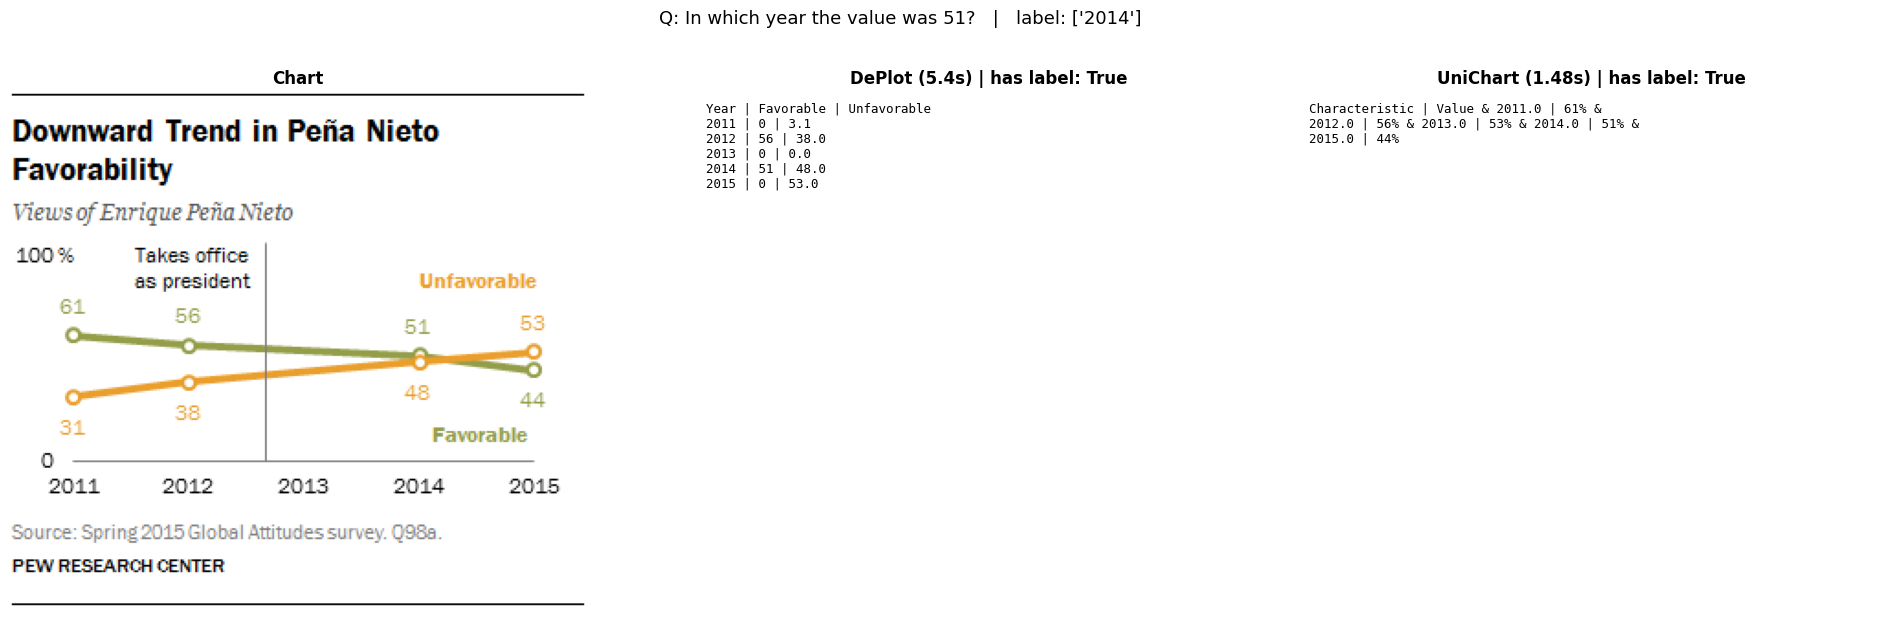

In [ ]:
import textwrap
import matplotlib.pyplot as plt

def pretty(text, max_lines=18, width=45):
    """Make model output readable: split rows, wrap long lines, cap length."""
    text = text.replace("&&", "\n")        # UniChart row separator (see note below)
    lines = []
    for ln in text.split("\n"):
        lines.extend(textwrap.wrap(ln.strip(), width) or [""])
    if len(lines) > max_lines:
        lines = lines[:max_lines] + ["... (truncated)"]
    return "\n".join(lines)

def show_results(df_ocr, test_df, n=3):
    for i in range(min(n, len(df_ocr))):
        r = df_ocr.iloc[i]
        img = decode_chart_image(test_df.iloc[i]).convert("RGB")

        fig, axes = plt.subplots(1, 3, figsize=(20, 6),
                                 gridspec_kw={"width_ratios": [1.3, 1, 1]})

        # 1) the chart
        axes[0].imshow(img)
        axes[0].set_title("Chart", fontweight="bold")

        # 2) DePlot output
        axes[1].text(0.02, 0.98, pretty(r["deplot_table"]), va="top", ha="left",
                     family="monospace", fontsize=9, transform=axes[1].transAxes)
        axes[1].set_title(f"DePlot ({r['deplot_s']}s) | has label: {r['deplot_has_label']}",
                          fontweight="bold")

        # 3) UniChart output
        axes[2].text(0.02, 0.98, pretty(r["unichart_table"]), va="top", ha="left",
                     family="monospace", fontsize=9, transform=axes[2].transAxes)
        axes[2].set_title(f"UniChart ({r['unichart_s']}s) | has label: {r['unichart_has_label']}",
                          fontweight="bold")

        for ax in axes:
            ax.axis("off")
        # re-show the titles since axis("off") hides ticks only, not titles
        fig.suptitle(f"Q: {r['query']}   |   label: {r['label']}", fontsize=13, y=1.02)
        plt.tight_layout()
        plt.show()

show_results(df_ocr, test_df, n=3)

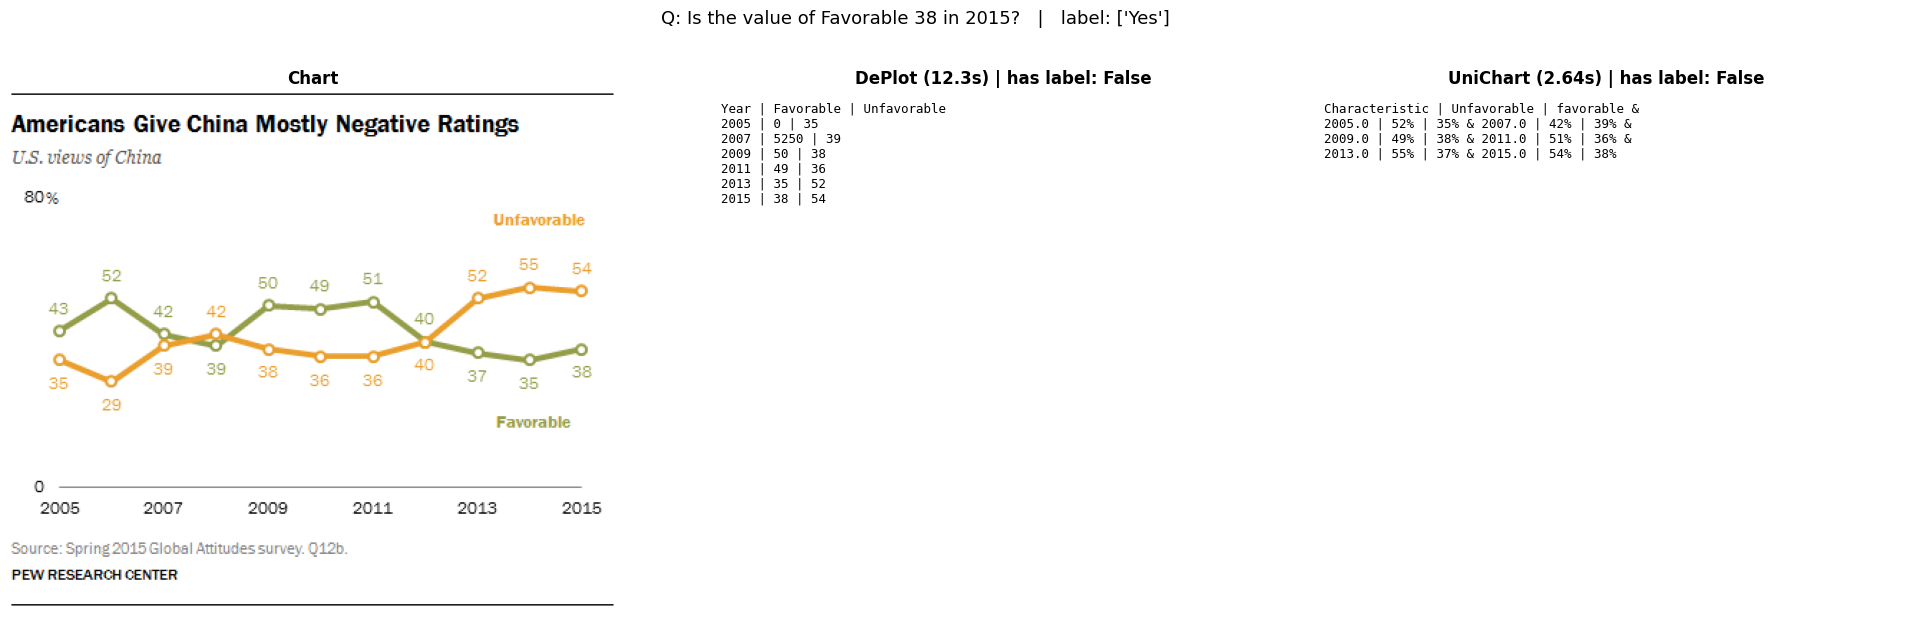

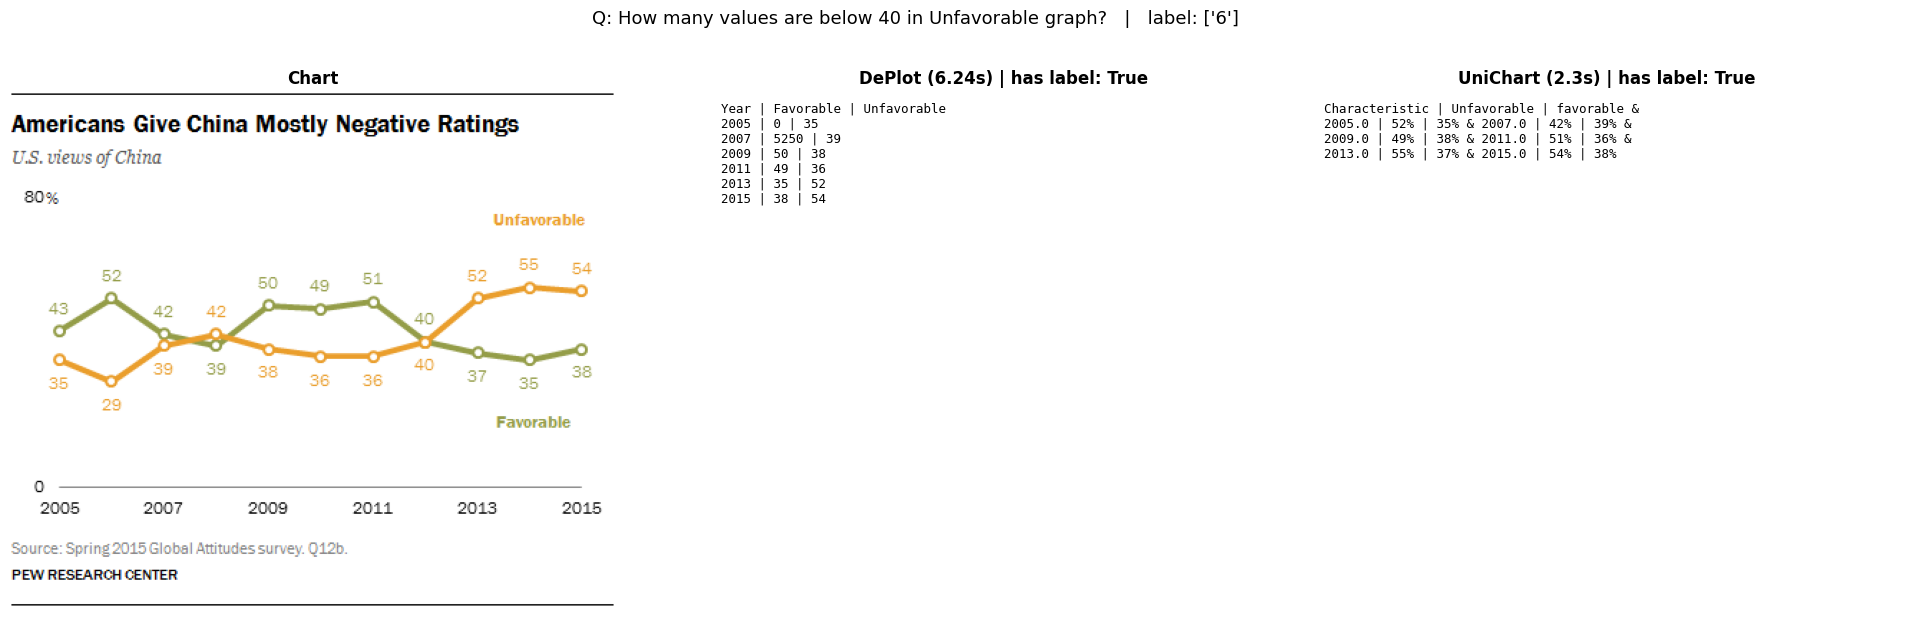

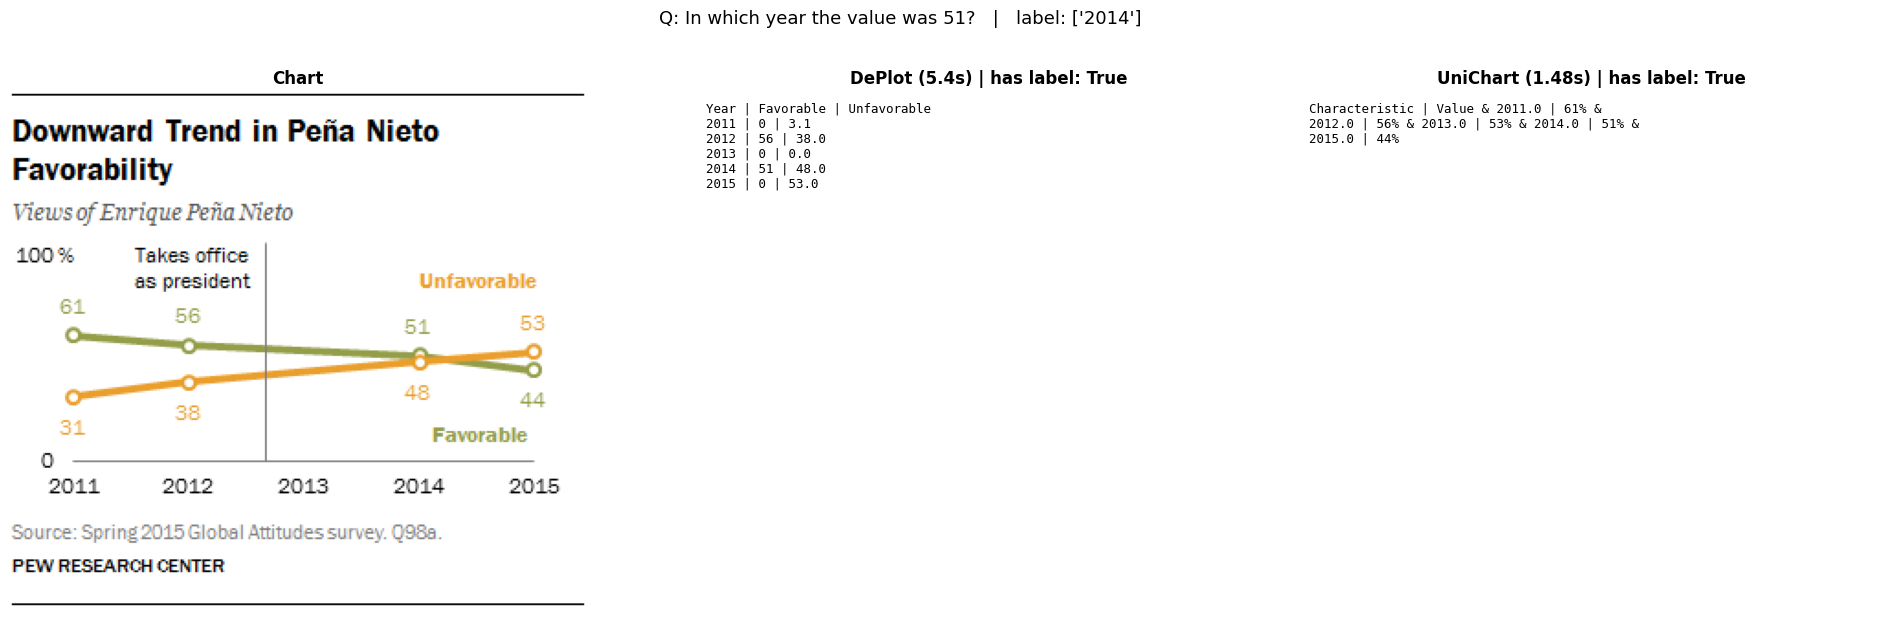

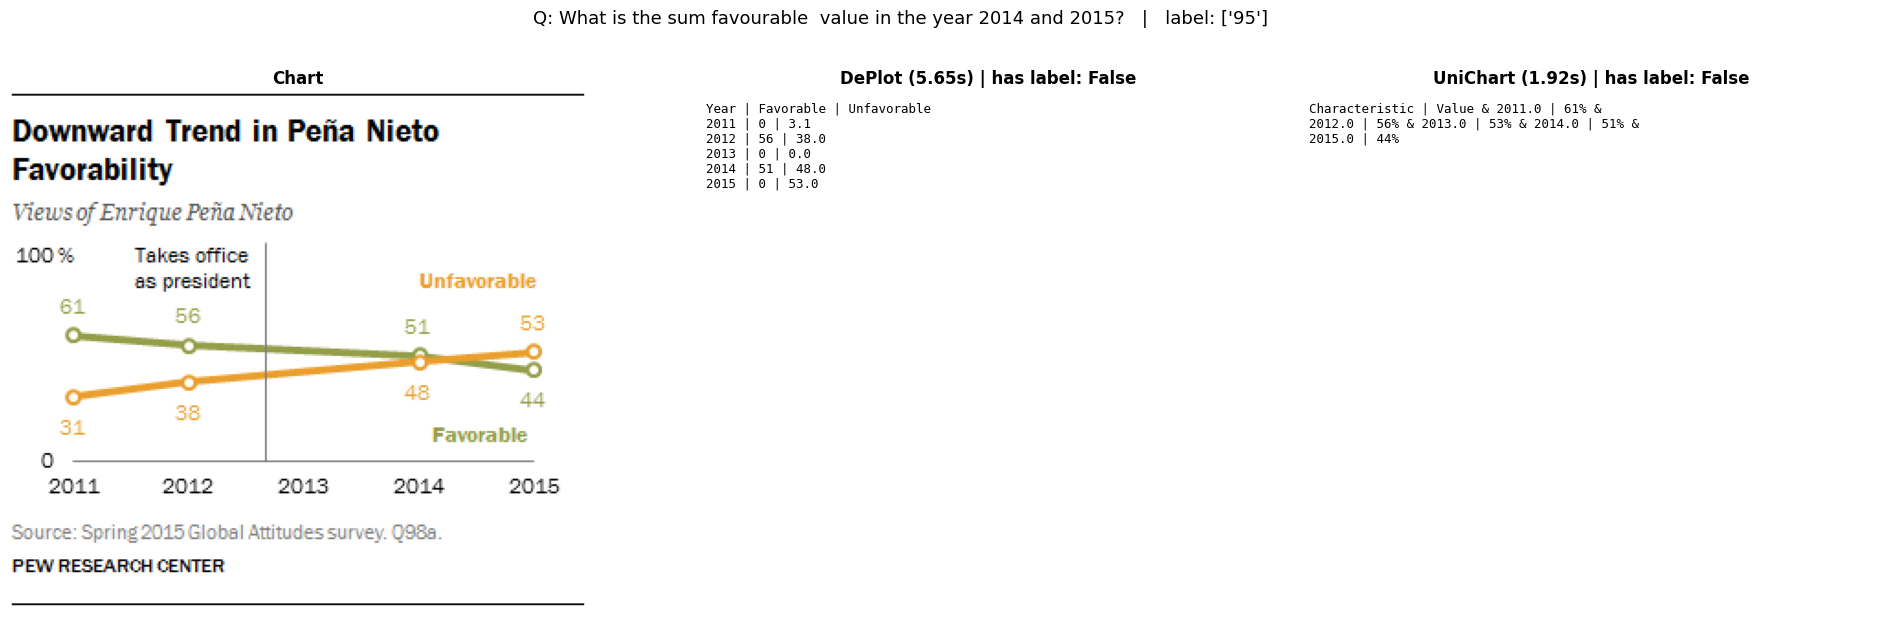

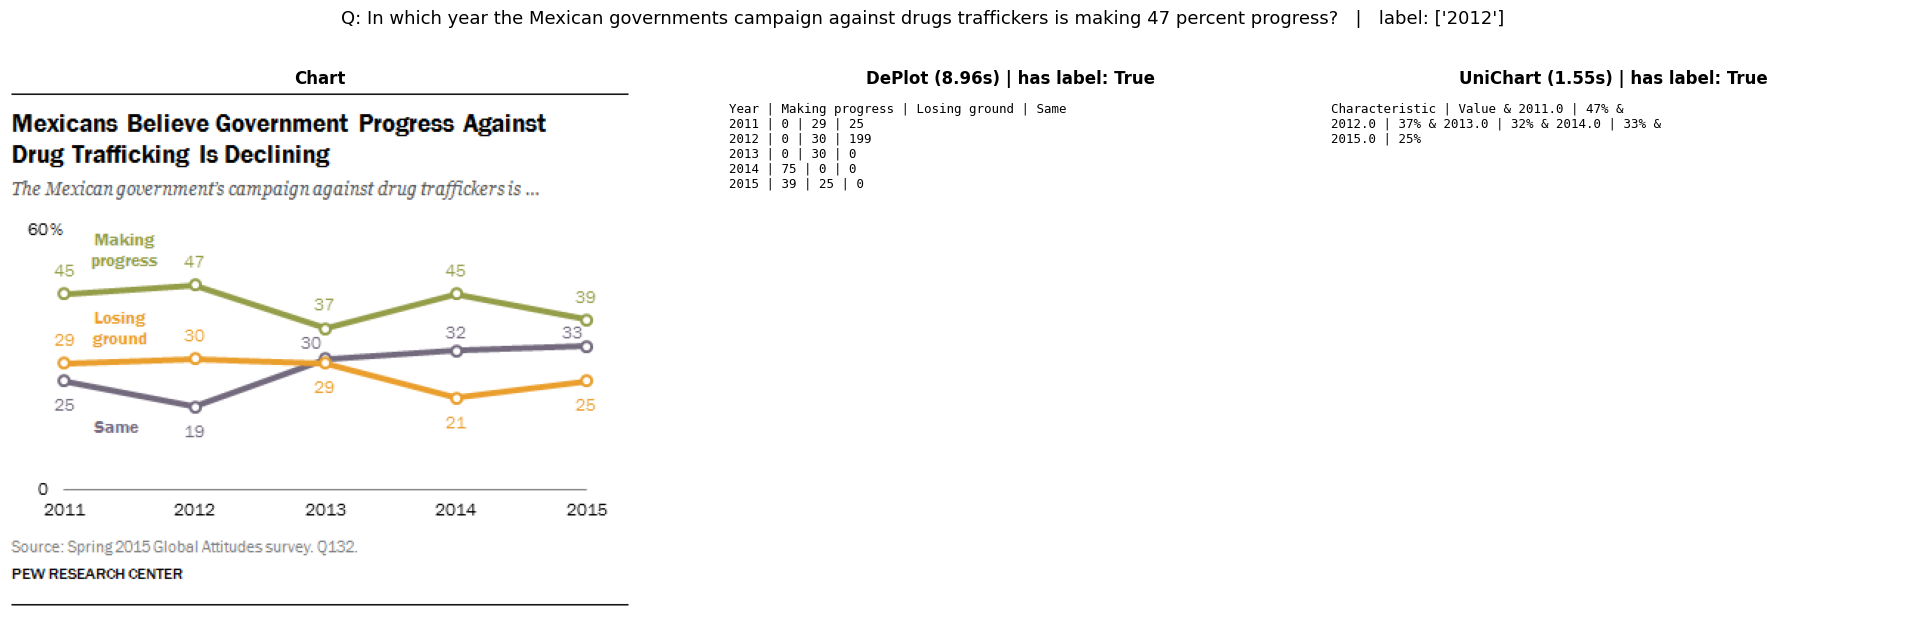

In [13]:
show_results(df_ocr, test_df, n=30)

Further Steps take these models and run it on the entire 3 partioned data set and then pass it to a llm and run inference we can do it on a sample also just to get a baseline accuracy measure which we can move unwards from later.